In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("koryakinp/chess-positions")

print("Path to dataset files:", path)

ModuleNotFoundError: No module named 'kagglehub'

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random as rd
import re

: 

In [4]:
import glob
import os

base_path = r"D:\chess_position"

if not os.path.exists(base_path):
    print(f"Base path does not exist: {base_path}")
else:
    print(f"Base path exists: {base_path}")

train_path = glob.glob(os.path.join(base_path, "train", "*.jpeg"))
test_path = glob.glob(os.path.join(base_path, "test", "*.jpeg"))

print(f"Number of training images found: {len(train_path)}")
print(f"Number of testing images found: {len(test_path)}")

if train_path:
    print(f"Sample training image: {train_path[0]}")
if test_path:
    print(f"Sample testing image: {test_path[0]}")


Base path exists: D:\chess_position
Number of training images found: 80000
Number of testing images found: 20000
Sample training image: D:\chess_position\train\1b1B1b2-2pK2q1-4p1rB-7k-8-8-3B4-3rb3.jpeg
Sample testing image: D:\chess_position\test\1b1B1Qr1-7p-6r1-2P5-4Rk2-1K6-4B3-8.jpeg


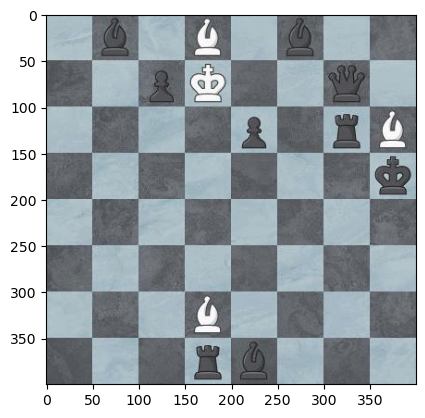

In [5]:
sam=cv2.imread(train_path[0])
plt.imshow(sam)

In [6]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten

In [7]:
piece_symbols = 'prbnkqPRBNKQ'
train_size =20000
test_size = 4000
train = train_path[:train_size]
test= test_path[:test_size]

def image_FEN(image_path):
    file_name = os.path.splitext(os.path.basename(image_path))[0]
    # Assuming the filename itself is the FEN notation
    fen = file_name.replace("-", "/")  # Replace '-' with '/' to match FEN notation
    return fen

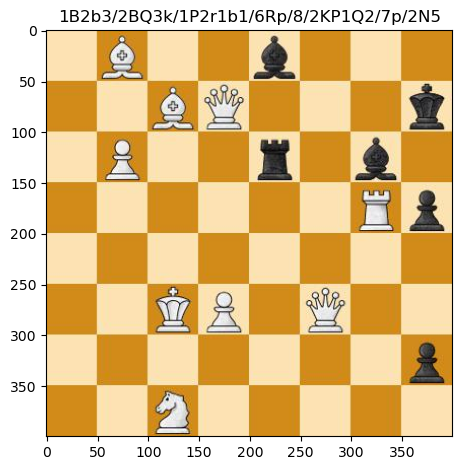

In [8]:
rand = np.random.randint(0, train_size)
img_path =train[rand]
img_moves =  image_FEN(img_path)
img_rand=cv2.imread(img_path)
plt.imshow(cv2.cvtColor(img_rand, cv2.COLOR_BGR2RGB))
plt.title(img_moves)
plt.tight_layout()
plt.show()

In [9]:
! pip install python-chess

The FEN notation of the image is:  1B2b3/2BQ3k/1P2r1b1/6Rp/8/2KP1Q2/7p/2N5


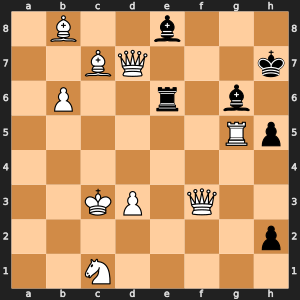

In [10]:
import chess.svg
import chess
print("The FEN notation of the image is: ", img_moves)
board = chess.Board(img_moves.replace('-', '/'))
chess.svg.board(board, size=300)

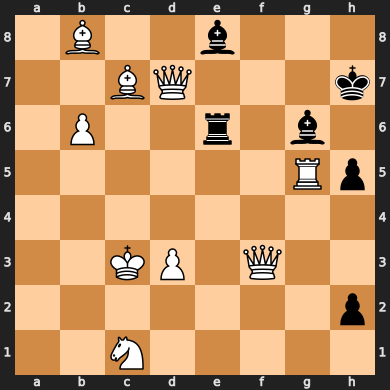

In [11]:
board

In [12]:
def prepro(image_paths):
  processed_img = []
  for path in image_paths:
    img= cv2.imread(path)
    img = cv2.resize(img, (240,240))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img = (img-np.min(img))/(np.max(img)-np.min(img))
    processed_img.append(img)
  return processed_img

In [13]:
samples =rd.sample(train, 9)

In [14]:
prepro_img = prepro(samples)


In [15]:
prepro_img[0].shape

(240, 240)

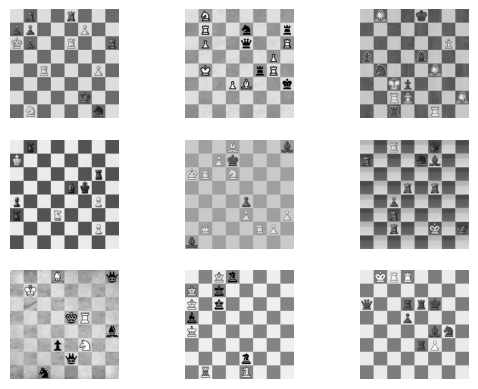

In [16]:
for i in range(9):
  plt.subplot(3,3,i+1)
  plt.imshow(prepro_img[i], cmap='gray')
  plt.axis('off')

(720, 720)

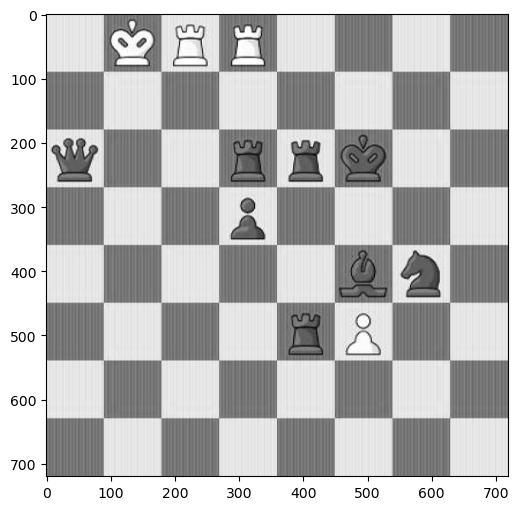

In [17]:
img = np.array(cv2.imread(samples[8]))
new_img=img.reshape(img.shape[0], (img.shape[1]*img.shape[2]))
new_img= cv2.resize(new_img, (720, 720),interpolation=cv2.INTER_CUBIC)
plt.figure(figsize=(6, 6))
plt.imshow(new_img, cmap='gray')
new_img.shape

In [18]:
from sklearn.decomposition import PCA

pca = PCA()
pca.n_components = 5
img_transformed = pca.fit_transform(new_img)

percentage_var_explained = pca.explained_variance_ / np.sum(pca.explained_variance_);

cum_var_explained = np.cumsum(percentage_var_explained)

reserved =np.round(np.sum(pca.explained_variance_ratio_),3)*100

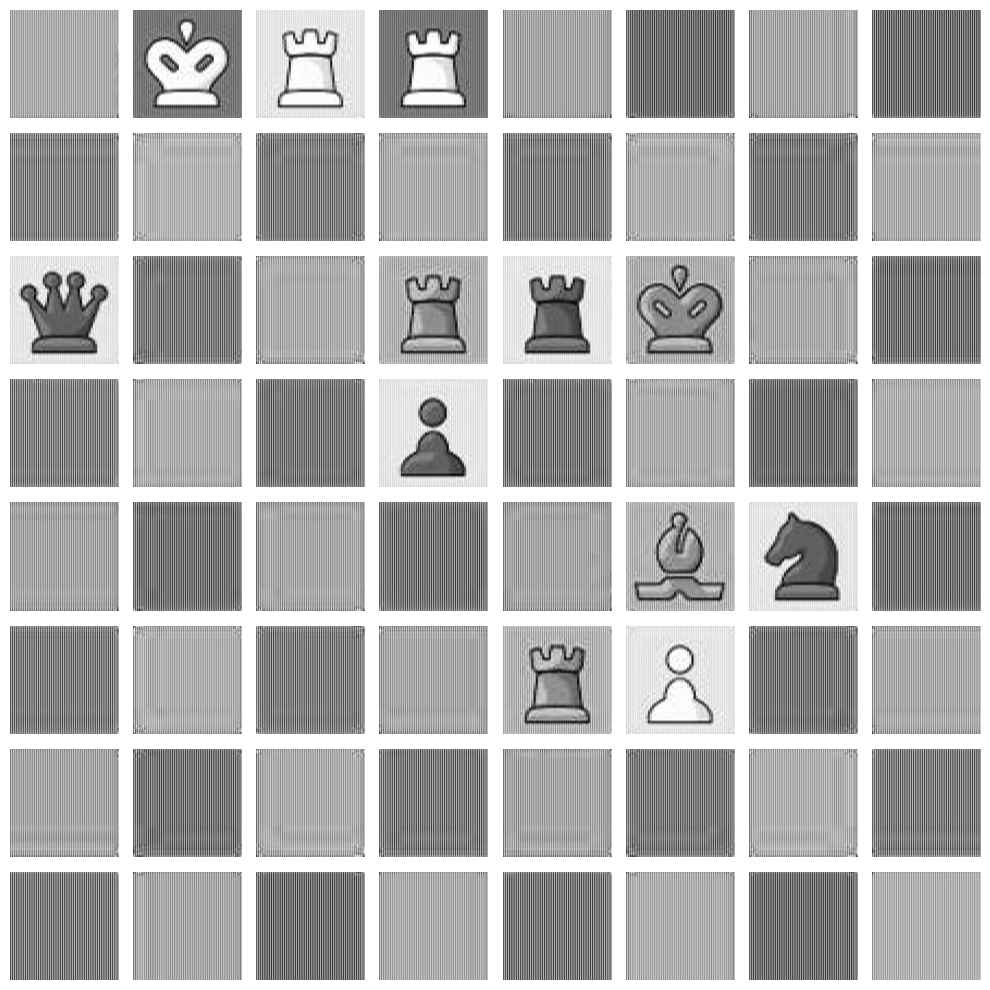

(64, 720, 720)

In [19]:
def image_to_squares_pca(img,heights,widths):
  squares = []
  for i in range(0,8):
    for j in range(0,8):
      new_img =img[i*heights//8:i*heights//8+heights//8,j*widths//8:j*widths//8+widths//8]
      new_img=new_img.reshape(new_img.shape[0], (new_img.shape[1]*new_img.shape[2]))
      new_img= cv2.resize(new_img, (720, 720),interpolation=cv2.INTER_CUBIC)
      squares.append(new_img)
  return np.array(squares)

img = np.array(cv2.imread(samples[8]))
sqaures= image_to_squares_pca(img,400,400)
fig = plt.figure(figsize=(10, 10))
columns = 8
rows = 8
for i, img in zip(range(1, columns*rows +1),sqaures):
    fig.add_subplot(rows, columns, i)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.tight_layout()
plt.show()
sqaures.shape

In [20]:
def images_to_square(img,width,height):
  squares = []
  for i in range(0,8):
    for j in range(0,8):
      new_img = img[i*height//8:i*height//8+height//8,j*width//8:j*width//8+width//8]
      squares.append(new_img)

  return np.array(squares)



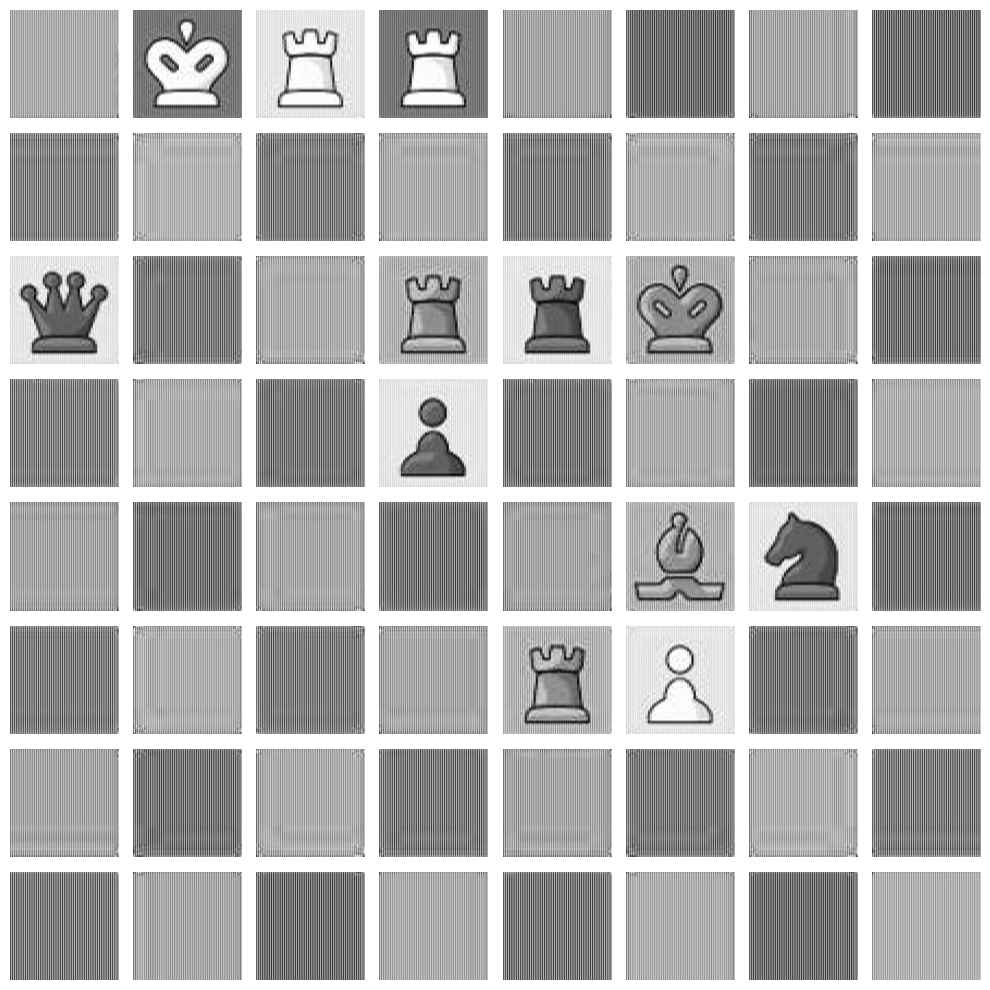

(64, 720, 720)

In [21]:
squares = images_to_square(prepro_img[0],240,240)

fig = plt.figure(figsize=(10, 10))
columns = 8
rows = 8
for i, img in zip(range(1, columns*rows +1),sqaures):
    fig.add_subplot(rows, columns, i)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.tight_layout()
plt.show()
sqaures.shape

In [84]:
import cv2
import numpy as np

def preprocess_image(img_path):
    height = 240
    width = 240

    # Load the image in grayscale
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Image at {img_path} could not be loaded.")
    print(f"Loaded image shape: {img.shape}")

    # Resize the image while preserving the aspect ratio
    h, w = img.shape[:2]
    scale = min(width / w, height / h)
    resized = cv2.resize(img, (int(w * scale), int(h * scale)))
    print(f"Resized image shape: {resized.shape}")

    # Pad the resized image to make it square
    delta_w = width - resized.shape[1]
    delta_h = height - resized.shape[0]
    top, bottom = delta_h // 2, delta_h - (delta_h // 2)
    left, right = delta_w // 2, delta_w - (delta_w // 2)
    padded = cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_CONSTANT, value=0)
    print(f"Padded image shape: {padded.shape}")

    # Normalize the image to [0, 1]
    padded = padded.astype('float32')
    normalized = (padded - np.min(padded)) / (np.max(padded) - np.min(padded) + 1e-8)
    print(f"Normalized image stats: min={np.min(normalized)}, max={np.max(normalized)}")

    return normalized

    # # Split the image into squares (assuming images_to_square is defined)
    # # If images_to_square is undefined, temporarily skip this step
    # try:
    #     squares = images_to_square(normalized, height, width)
    #     print(f"Processed into squares, final shape: {squares.shape}")
    # except NameError:
    #     print("images_to_square function is not defined, skipping this step.")
    #     squares = normalized

    # return squares


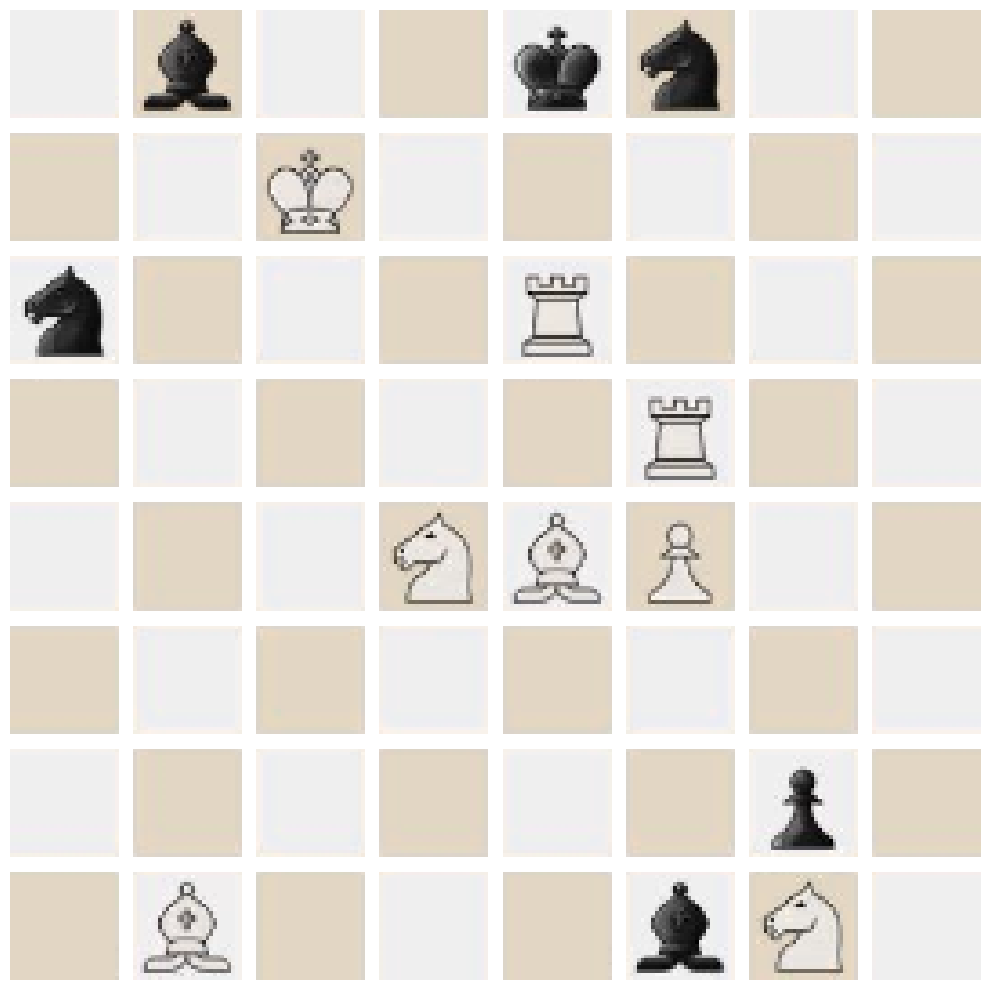

(64, 30, 30, 3)

In [23]:
sqaures=preprocess_image(train[444])

fig = plt.figure(figsize=(10, 10))
columns = 8
rows = 8
for i, img in zip(range(1, columns*rows +1),sqaures):
    fig.add_subplot(rows, columns, i)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.tight_layout()
plt.show()
sqaures.shape

In [24]:
def onehot_from_fen(fen):
    eye = np.eye(13)
    output = np.empty((0, 13))
    fen = re.sub('[-]', '', fen)
    fen = re.sub(r'[^prbnkqPRBNKQ12345678]', '', fen)

    for char in fen:
        if(char in '12345678'):
            output = np.append(
              output, np.tile(eye[12], (int(char), 1)), axis=0)
        else:
            idx = piece_symbols.index(char)
            output = np.append(output, eye[idx].reshape((1, 13)), axis=0)

    return output

def fen_from_onehot(one_hot):
    output = ''
    for j in range(8):
        for i in range(8):
            if(one_hot[j][i] == 12):
                output += ' '
            else:
                output += piece_symbols[one_hot[j][i]]
        if(j != 7):
            output += '-'

    for i in range(8, 0, -1):
        output = output.replace(' ' * i, str(i))

    return output

In [25]:
def train_gen(features):
    for i, img in enumerate(features):
        y = onehot_from_fen(image_FEN(img))
        x = preprocess_image(img)
        yield x, y

def pred_gen(features):
    for i, img in enumerate(features):
        y = onehot_from_fen(image_FEN(img))
        x = preprocess_image(img)
        yield x, y

In [34]:
model = Sequential()

model.add(Conv2D(32,(2,2), strides=(2,2), activation='relu', input_shape=(30,30,3)))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dense(13, activation='softmax'))



In [35]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
EPOCHS = 100

In [36]:
hist = model.fit(train_gen(train), steps_per_epoch=train_size//EPOCHS, epochs=EPOCHS,validation_data=pred_gen(test), validation_steps=test_size//EPOCHS)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8003 - loss: 0.9226 - val_accuracy: 0.9461 - val_loss: 0.2571
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9504 - loss: 0.2259 - val_accuracy: 0.8813 - val_loss: 0.4945
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9665 - loss: 0.1460 - val_accuracy: 0.9906 - val_loss: 0.0502
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9909 - loss: 0.0474 - val_accuracy: 0.9977 - val_loss: 0.0250
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9943 - loss: 0.0351 - val_accuracy: 0.9977 - val_loss: 0.0172
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9952 - loss: 0.0269 - val_accuracy: 0.9949 - val_loss: 0.0274
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9968 - loss: 0.0185 - val_accuracy: 0.9992 - val_loss: 0.0102
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9980 - loss: 0.0144 - va

In [37]:
import matplotlib.image as mpimg
def display_with_predicted_fen(image):
    plt.figure(figsize=(5,5))
    pred = model.predict(preprocess_image(image)).argmax(axis=1).reshape(-1, 8, 8)
    fen = fen_from_onehot(pred[0])
    imgplot = plt.imshow(mpimg.imread(image))
    plt.axis('off')
    plt.title(fen)
    plt.show()
    return fen

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step 


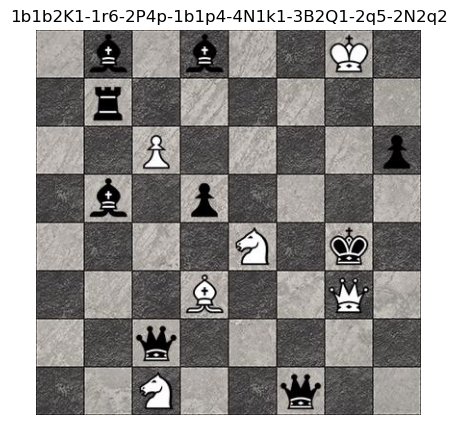

In [38]:
pred =display_with_predicted_fen(test[2])

In [81]:
board = chess.Board(pred.replace('-', '/'))

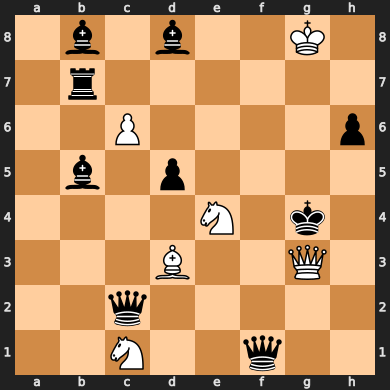

In [82]:
board

In [85]:
model.save("my_model.keras")


In [56]:
imga = cv2.imread(r'C:\Users\ASUS\OneDrive\Desktop\chess_ai\Backend\CNN\test.jpg')

In [63]:
predt = display_with_predicted_fen(r'C:\Users\ASUS\OneDrive\Desktop\chess_ai\Backend\CNN\test.jpg')

ValueError: Exception encountered when calling Sequential.call().

[1mCannot take the length of shape with unknown rank.[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=<unknown>, dtype=float32)
  • training=False
  • mask=None

<Figure size 500x500 with 0 Axes>

In [58]:
board = chess.Board(predt.replace('-', '/'))

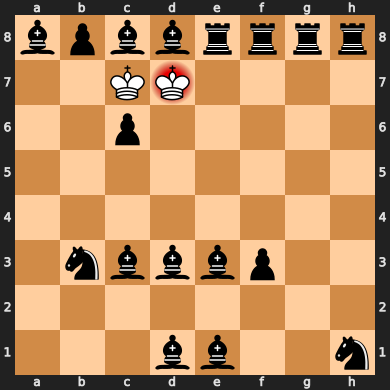

In [59]:
board

In [85]:
lol=preprocess_image(r'C:\Users\ASUS\OneDrive\Desktop\chess_ai\Backend\CNN\test.jpg')
com= cv2.imread(r'C:\Users\ASUS\OneDrive\Desktop\chess_ai\Backend\CNN\test.jpg')

Loaded image shape: (1200, 540)
Resized image shape: (240, 108)
Padded image shape: (240, 240)
Normalized image stats: min=0.0, max=1.0


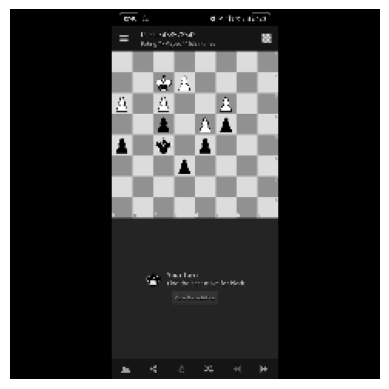

In [86]:
plt.imshow(lol, cmap='gray')  # Use 'cmap="gray"' for grayscale images
plt.axis('off')  # Turn off axis labels
plt.show()

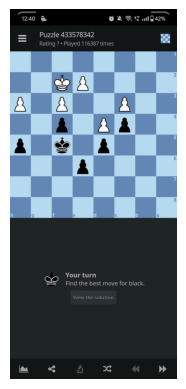

: 

In [ ]:
plt.imshow(com)
plt.axis('off')
plt.show()